In [1]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
df = pd.read_csv("datasets/movie.csv")
df.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


### 1. Metin Temizleme Notu
`CountVectorizer` ve `TfidfVectorizer` varsayılan olarak metinleri otomatik küçük harfe çevirir (`lowercase=True`).
Pandas sütununda manuel yapmak isterseniz `df["text"].str.lower()` kullanılır.

In [3]:
# Pandas ile kucuk harfe cevirme ornegi:
df["clean_text"] = df["text"].str.lower()
df[["text", "clean_text"]].head(2)

,text,clean_text
0,I grew up (b. 1965) watching and loving the Th...,i grew up (b. 1965) watching and loving the th...
1,"When I put this movie in my DVD player, and sa...","when i put this movie in my dvd player, and sa..."


### 2. CountVectorizer vs TfidfVectorizer: Küçük Örnek ile Karşılaştırma
- **CountVectorizer:** Kelimelerin frekansını (kaç kere geçtiğini) sayar.
- **TfidfVectorizer:** Her belgede çok geçen kelimeleri (örn. "the", "movie") cezalandırır, o belgeye özgü kelimelerin ağırlığını artırır.

In [4]:
ornek_metinler = [
    "The movie was great and fantastic",
    "The movie was terrible and bad",
    "The movie was great great great"
]

# CountVectorizer (Frekans sayımı)
cv = CountVectorizer()
cv_matrix = cv.fit_transform(ornek_metinler)
df_cv = pd.DataFrame(cv_matrix.toarray(), columns=cv.get_feature_names_out())

# TfidfVectorizer (TF-IDF ağırlığı)
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(ornek_metinler)
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf.get_feature_names_out())

print("=== CountVectorizer (Kelimelerin Geçiş Sayıları) ===")
display(df_cv)

print("\n=== TfidfVectorizer (Önem Ağırlıkları: 0-1 Arası Normalize) ===")
display(df_tfidf.round(3))

=== CountVectorizer (Kelimelerin Geçiş Sayıları) ===


,and,bad,fantastic,great,movie,terrible,the,was
0,1,0,1,1,1,0,1,1
1,1,1,0,0,1,1,1,1
2,0,0,0,3,1,0,1,1



=== TfidfVectorizer (Önem Ağırlıkları: 0-1 Arası Normalize) ===


,and,bad,fantastic,great,movie,terrible,the,was
0,0.425,0.000,0.559,0.425,0.330,0.000,0.330,0.330
1,0.399,0.525,0.000,0.000,0.310,0.525,0.310,0.310
2,0.000,0.000,0.000,0.912,0.236,0.000,0.236,0.236


### 3. IMDB Veri Seti Üzerinde Karşılaştırma
IMDB veri setindeki ilk 1000 yorum üzerinde en önemli ve en sık geçen kelimeleri inceleyelim.

In [5]:
# Ilk 1000 film yorumu ile hizli analiz
ornek_df = df.head(1000)

# stop_words="english" ile anlamsiz sik kelimeleri (the, a, is vb.) eliyoruz
cv_imdb = CountVectorizer(stop_words="english", max_features=10)
tfidf_imdb = TfidfVectorizer(stop_words="english", max_features=10)

X_cv = cv_imdb.fit_transform(ornek_df["text"])
X_tfidf = tfidf_imdb.fit_transform(ornek_df["text"])

print("CountVectorizer En Çok Geçen 10 Kelime:")
print(list(cv_imdb.get_feature_names_out()))

print("\nTfidfVectorizer En Belirleyici 10 Kelime:")
print(list(tfidf_imdb.get_feature_names_out()))

# Ilk yorumun TF-IDF skor tablosu:
ilk_yorum_skorlari = pd.DataFrame(X_tfidf[0].toarray(), columns=tfidf_imdb.get_feature_names_out())
print("\nIlk Yorumun TF-IDF Vektor Temsili:")
display(ilk_yorum_skorlari)

CountVectorizer En Çok Geçen 10 Kelime:
['bad', 'br', 'film', 'good', 'just', 'like', 'movie', 'really', 'story', 'time']

TfidfVectorizer En Belirleyici 10 Kelime:
['bad', 'br', 'film', 'good', 'just', 'like', 'movie', 'really', 'story', 'time']

Ilk Yorumun TF-IDF Vektor Temsili:


,bad,br,film,good,just,like,movie,really,story,time
0,0.0,0.0,0.737048,0.0,0.0,0.0,0.675841,0.0,0.0,0.0


In [8]:
tfidf = TfidfVectorizer(stop_words= "english", max_features= 1000)

X_tfidf = tfidf.fit_transform(ornek_df["text"])

ortalama_agirliklar = X_tfidf.mean(axis= 0).A1

tfidf_analiz = pd.DataFrame({
    "kelime": tfidf.get_feature_names_out(),
    "ortalama_tfidf": ortalama_agirliklar
})

tfidf_analiz = tfidf_analiz.sort_values(
    "ortalama_tfidf", ascending= False
)
tfidf_analiz.head(20)

,kelime,ortalama_tfidf
97,br,0.158787
576,movie,0.084638
316,film,0.069108
499,like,0.040355
457,just,0.038607
368,good,0.032562
694,really,0.030043
374,great,0.028326
828,story,0.028256
883,time,0.028253


In [11]:
ornek_df = df.head(1000)

cv_imdb = CountVectorizer(
    stop_words= "english",
    max_features= 1000
)

X_cv = cv_imdb.fit_transform(ornek_df["text"])

kelime_frekansları = X_cv.sum(axis= 0).A1

frekans_df = pd.DataFrame({
    "kelime": cv_imdb.get_feature_names_out(),
    "frekans": kelime_frekansları
})

frekans_df = frekans_df.sort_values(
    "frekans",
    ascending= False
)
frekans_df.head(20)

,kelime,frekans
97,br,4226
576,movie,1872
316,film,1580
499,like,865
457,just,821
368,good,600
883,time,507
694,really,499
828,story,463
64,bad,427


In [12]:
metin = [
    "the movie was not good",
    "the movie was very good"
]

cv_unigram = CountVectorizer(ngram_range= (1,1))
X_uni = cv_unigram.fit_transform(metin)

print(cv_unigram.get_feature_names_out())

cv_bigram = CountVectorizer(ngram_range= (1,2))
X_bi = cv_bigram.fit_transform(metin)

print(cv_bigram.get_feature_names_out())

['good' 'movie' 'not' 'the' 'very' 'was']
['good' 'movie' 'movie was' 'not' 'not good' 'the' 'the movie' 'very'
 'very good' 'was' 'was not' 'was very']


In [13]:
print(df.columns.to_list())
print(df[["text","label"]].isna().sum())
print(df["label"].value_counts())

['text', 'label', 'clean_text']
text     0
label    0
dtype: int64
label
0    20019
1    19981
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [15]:
veri = df.dropna(subset= ["text","label"]).copy()

In [16]:
X = veri["text"]
y = veri["label"]

In [18]:
X_train, X_test,y_train,y_test = train_test_split(X,y,test_size= 0.2,random_state= 42)

In [19]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words= "english", max_features= 10000)),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [20]:
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",10000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [21]:
y_pred = model.predict(X_test)

In [22]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.88775
              precision    recall  f1-score   support

           0       0.90      0.87      0.89      3966
           1       0.88      0.90      0.89      4034

    accuracy                           0.89      8000
   macro avg       0.89      0.89      0.89      8000
weighted avg       0.89      0.89      0.89      8000



In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [28]:
etiketler = model.classes_
cm = confusion_matrix(y_test, y_pred, labels= etiketler)

In [29]:
gosterim = ConfusionMatrixDisplay(
    confusion_matrix= cm,
    display_labels= etiketler
)

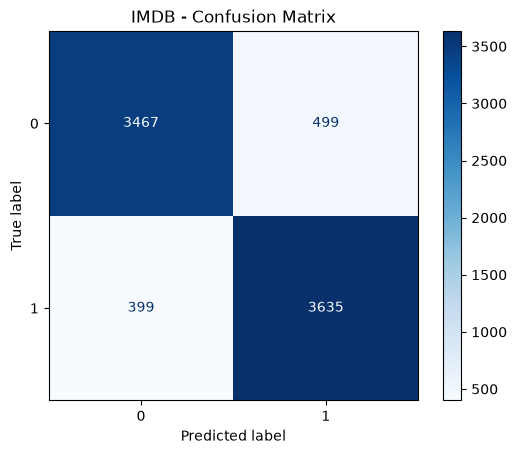

In [30]:
gosterim.plot(cmap= "Blues", values_format= "d")
plt.title("IMDB - Confusion Matrix")
plt.show()

In [31]:
yanlislar = pd.DataFrame({
    "yorum": X_test,
    "gercek_etiket": y_test,
    "tahmin": y_pred
})

yanlislar[
    yanlislar["gercek_etiket"] != yanlislar["tahmin"]
]

yanlislar.head(10)

,yorum,gercek_etiket,tahmin
32823,The central theme in this movie seems to be co...,0,0
16298,"An excellent example of ""cowboy noir"", as it's...",1,1
28505,The ending made my heart jump up into my throa...,0,1
6689,Only the chosen ones will appreciate the quali...,1,1
26893,"This is a really funny film, especially the se...",1,1
36572,"Sure, we all like bad movies at one time or an...",0,0
12335,"Why?!! This was an insipid, uninspired and emb...",0,0
29591,This is one of those movies that has everythin...,1,1
18948,i saw this film over 20 years ago and still re...,1,1
31067,This true story of Carlson's Raiders is more o...,0,0


In [33]:
tfidf = model.named_steps["tfidf"]

ornek_yorum = X_test.iloc[0]

vektor = tfidf.transform([ornek_yorum])

print(ornek_yorum)

print("\nVektörün boyutu:", vektor.shape)
print("Sıfır olmayan özellik sayısı:", vektor.nnz)

kelimeler = tfidf.get_feature_names_out()
skorlar = vektor.toarray().ravel()

indeksler = skorlar.argsort()[::-1]
sonuclar = []

for i in indeksler:
    if skorlar[i] > 0:
        sonuclar.append({
            "kelime": kelimeler[i],
            "tfidf_skoru": round(skorlar[i], 4)
        })



print(pd.DataFrame(sonuclar).head(10))

print(model.predict([ornek_yorum])[0])

The central theme in this movie seems to be confusion, as the relationships, setting, acting and social context all lead to the same place: confusion. Even Harvey Keitel appears to be out of his element, and lacks his usual impeccable clarity, direction and intensity. To make matters worse, his character's name is 'Che', and we are only told (directly, by the narrator) well into the film that he is not 'that' Che, just a guy named Che. The family relationships remain unclear until the end of the film, and once defined, the family is divided - the younger generation off to America. So cliché. Other reviews discuss how the movie depicts the impact of the revolution on a boy's family; however the political stance of the director is murky at best, and we are never quite sure who is responsible for what bloodshed. So they lost their property (acquired by gambling profits) - so what? Refusing to take a political stand, when making a movie about the Cuban revolution, is an odd and cowardly ch

In [34]:
tfidf = model.named_steps["tfidf"]

ornek_yorum = X_test.iloc[0]

vektor = tfidf.transform([ornek_yorum])

print("Matris boyutu:", vektor.shape)
print("Sıfır olmayan değer sayısı:", vektor.nnz)
print("Toplam özellik sayısı:", vektor.shape[1])

Matris boyutu: (1, 10000)
Sıfır olmayan değer sayısı: 108
Toplam özellik sayısı: 10000


In [36]:
kelimeler = tfidf.get_feature_names_out()
skorlar = vektor.toarray().ravel()

sonuclar = pd.DataFrame({
    "kelime": kelimeler,
    "tfidf_skoru": skorlar
})

sonuclar = sonuclar[sonuclar["tfidf_skoru"] > 0]
sonuclar = sonuclar.sort_values(
    "tfidf_skoru", ascending= False
)

sonuclar.head(10)

,kelime,tfidf_skoru
1565,che,0.350167
7321,relationships,0.236176
1692,clarity,0.223592
3382,family,0.205935
7499,revolution,0.185169
1957,confusion,0.180019
6722,political,0.145578
3082,english,0.131418
4984,keitel,0.115778
2242,cuban,0.114890


In [39]:
karsilastirma = pd.DataFrame({
    "Gercek_Etiket": y_test,
    "Model_Tahmini": y_pred
})

karsilastirma.head(10)

,Gercek_Etiket,Model_Tahmini
32823,0,0
16298,1,1
28505,0,1
6689,1,1
26893,1,1
36572,0,0
12335,0,0
29591,1,1
18948,1,1
31067,0,0


In [40]:
karsilastirma["Dogru_Tahmin"] = (
    karsilastirma["Gercek_Etiket"]
    == karsilastirma["Model_Tahmini"]
)

display(karsilastirma.head(10))

print("Doğru tahmin sayısı:",
      karsilastirma["Dogru_Tahmin"].sum())

print("Yanlış tahmin sayısı:",
      (~karsilastirma["Dogru_Tahmin"]).sum())

print("Doğruluk oranı:",
      round(karsilastirma["Dogru_Tahmin"].mean(), 4))


,Gercek_Etiket,Model_Tahmini,Dogru_Tahmin
32823,0,0,True
16298,1,1,True
28505,0,1,False
6689,1,1,True
26893,1,1,True
36572,0,0,True
12335,0,0,True
29591,1,1,True
18948,1,1,True
31067,0,0,True


Doğru tahmin sayısı: 7102
Yanlış tahmin sayısı: 898
Doğruluk oranı: 0.8878


In [41]:
print("Test kümesindeki toplam yorum:", len(y_test))
print("Yanlış tahmin sayısı:", (~karsilastirma["Dogru_Tahmin"]).sum())

print("Doğruluk oranı:",
      round(karsilastirma["Dogru_Tahmin"].mean() * 100, 2), "%")

Test kümesindeki toplam yorum: 8000
Yanlış tahmin sayısı: 898
Doğruluk oranı: 88.78 %


In [42]:
yanlislar = karsilastirma[
    ~karsilastirma["Dogru_Tahmin"]
].copy()

yanlislar["Yorum"] = X_test.loc[yanlislar.index]

display(yanlislar.head(5))

,Gercek_Etiket,Model_Tahmini,Dogru_Tahmin,Yorum
28505,0,1,False,The ending made my heart jump up into my throa...
22241,1,0,False,Nothing new is this tired serio-comedy that wa...
34089,0,1,False,I give the show a six because of the fact that...
252,1,0,False,I'm giving this film 9 out of 10 only because ...
3434,1,0,False,OK so some of the plot points might be a bit o...


In [43]:
yanlislar = karsilastirma[
    ~karsilastirma["Dogru_Tahmin"]
].copy()

yanlislar["Yorum"] = X_test.loc[yanlislar.index]

display(
    yanlislar[
        ["Yorum", "Gercek_Etiket", "Model_Tahmini"]
    ].head(5)
)

,Yorum,Gercek_Etiket,Model_Tahmini
28505,The ending made my heart jump up into my throa...,0,1
22241,Nothing new is this tired serio-comedy that wa...,1,0
34089,I give the show a six because of the fact that...,0,1
252,I'm giving this film 9 out of 10 only because ...,1,0
3434,OK so some of the plot points might be a bit o...,1,0


In [44]:
for indeks, satir in yanlislar.head(3).iterrows():
    print("=" * 80)
    print("Yorum:", X_test.loc[indeks])
    print("Gerçek etiket:", y_test.loc[indeks])
    print("Model tahmini:", model.predict([X_test.loc[indeks]])[0])
    print()

Yorum: The ending made my heart jump up into my throat. I proceeded to leave the movie theater a little jittery. After all, it was nearly midnight. The movie was better than I expected. I don't know why it didn't last very long in the theaters or make as much money as anticipated. Definitely would recommend <br /><br />
Gerçek etiket: 0
Model tahmini: 1

Yorum: Nothing new is this tired serio-comedy that wastes the talents of Danny Glover and Whoopi Goldberg. Considering that this was produced by the stars and Spike Lee, it's pretty tame and tired stuff. And how come the Whoop never changes her hair or glasses over the many years this film covers? Blah!
Gerçek etiket: 1
Model tahmini: 0

Yorum: I give the show a six because of the fact that the show was in fact a platform for Damon Wayans as the Cosby Show was for Bill Cosby, it dealt with a lot of issues with humor and I felt that it in fact tailored to getting a laugh as opposed to letting the jokes come from the character. <br /><br

In [45]:
print(df["label"].value_counts())
print(df.groupby("label")["text"].head(2))

label
0    20019
1    19981
Name: count, dtype: int64
0    I grew up (b. 1965) watching and loving the Th...
1    When I put this movie in my DVD player, and sa...
4    Im a die hard Dads Army fan and nothing will e...
6    Finally watched this shocking movie last night...
Name: text, dtype: str


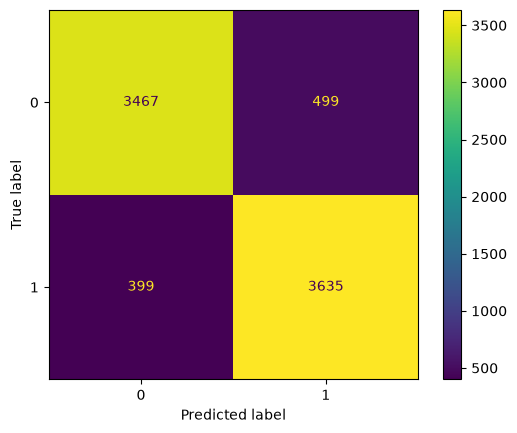

In [46]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix= cm
)

disp.plot()
plt.show()

In [47]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1-score:", f1_score(y_test, y_pred, average="weighted"))

Accuracy: 0.88775
Precision: 0.8879687361015899
Recall: 0.88775
F1-score: 0.8877205213749263


In [48]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.87      0.89      3966
           1       0.88      0.90      0.89      4034

    accuracy                           0.89      8000
   macro avg       0.89      0.89      0.89      8000
weighted avg       0.89      0.89      0.89      8000

